In [85]:
from pyscf import gto, scf
import numpy as np
import scipy.linalg, inspect
from pyscf import lib
from pyscf.scf import dhf
import scipy.linalg as sla
from pyscf.dft import numint
import pyvista as pv
import re
from collections import defaultdict
import matplotlib.pyplot as plt

#np.set_printoptions(formatter={"float": "{: 0.4f}".format})
np.set_printoptions(formatter={
    "float":   lambda x: f"{x: 0.4f}",
    'complex_kind': lambda x: f"{x.real: .3f}{x.imag:+.3f}j"
})

In [50]:
C_DEFAULT = lib.param.LIGHT_SPEED

In [52]:
# dyall_3zp
H_dyall_3zp  = [[0, 0, [9.01657212e+02, 1.0]],
      [0, 0, [1.34649031e+02, 1.0]],
      [0, 0, [3.05473364e+01, 1.0]],
      [0, 0, [8.62453493e+00, 1.0]],
      [0, 0, [2.80494579e+00, 1.0]],
      [0, 0, [1.00896460e+00, 1.0]],
      [0, 0, [3.91394822e-01, 1.0]],
      [0, 0, [1.60426029e-01, 1.0]],
      [0, 0, [6.71243724e-02, 1.0]],
      [1, 0, [1.23551545e+00, 1.0]],
      [1, 0, [2.93467565e-01, 1.0]]]

In [53]:
#dyall_ae4z
H_dyall_ae4z  = [[0, 0, [4.29410792e+03, 1.0]],
      [0, 0, [6.20952722e+02, 1.0]],
      [0, 0, [1.37359117e+02, 1.0]],
      [0, 0, [3.80348626e+01, 1.0]],
      [0, 0, [1.21810233e+01, 1.0]],
      [0, 0, [4.32951635e+00, 1.0]],
      [0, 0, [1.66557370e+00, 1.0]],
      [0, 0, [6.82099274e-01, 1.0]],
      [0, 0, [2.93685011e-01, 1.0]],
      [0, 0, [1.31152966e-01, 1.0]],
      [0, 0, [5.89277250e-02, 1.0]],
      [1, 0, [2.47030934e+00, 1.0]],
      [1, 0, [6.92601346e-01, 1.0]],
      [1, 0, [2.14026390e-01, 1.0]],
      [2, 0, [1.70913732e+00, 1.0]],
      [2, 0, [4.59764174e-01, 1.0]],
      [3, 0, [1.06034002e+00, 1.0]]]

In [54]:
#dyall_aae4zp
H_dyall_aae4zp  =[[0, 0, [4.29410792e+03, 1.0]],
      [0, 0, [6.20952722e+02, 1.0]],
      [0, 0, [1.37359117e+02, 1.0]],
      [0, 0, [3.80348626e+01, 1.0]],
      [0, 0, [1.21810233e+01, 1.0]],
      [0, 0, [4.32951635e+00, 1.0]],
      [0, 0, [1.66557370e+00, 1.0]],
      [0, 0, [6.82099274e-01, 1.0]],
      [0, 0, [2.93685011e-01, 1.0]],
      [0, 0, [1.31152966e-01, 1.0]],
      [0, 0, [5.89277250e-02, 1.0]],
      [0, 0, [1.79956932e-02, 1.0]],
      [1, 0, [2.47030934e+00, 1.0]],
      [1, 0, [6.92601346e-01, 1.0]],
      [1, 0, [2.14026390e-01, 1.0]],
      [1, 0, [6.44996399e-02, 1.0]],
      [2, 0, [1.70913732e+00, 1.0]],
      [2, 0, [4.59764174e-01, 1.0]],
      [2, 0, [1.44846445e-01, 1.0]],
      [3, 0, [1.06034002e+00, 1.0]],
      [3, 0, [3.14466631e-01, 1.0]]]


In [66]:
results = {}
light_speeds = [4, 40, 400]
basis_sets = {
    'dyall_3zp':    {'H': H_dyall_3zp},
    'dyall_ae4z':   {'H': H_dyall_ae4z},
    'dyall_aae4zp': {'H': H_dyall_aae4zp},
    'unc-ccpvdz':   'unc-ccpvdz',
    'unc-ccpvqz':   'unc-ccpvqz',
}
for name, b in basis_sets.items():
    m = gto.M(atom='H 0 0 0', basis=b, spin=1, verbose=0)
    print(f'{name:14s} nao = {m.nao_nr():3d}   спиноров (2c) = {2*m.nao_nr():3d}   4c-орбиталей = {4*m.nao_nr():3d}')

dyall_3zp      nao =  15   спиноров (2c) =  30   4c-орбиталей =  60
dyall_ae4z     nao =  37   спиноров (2c) =  74   4c-орбиталей = 148
dyall_aae4zp   nao =  53   спиноров (2c) = 106   4c-орбиталей = 212
unc-ccpvdz     nao =   7   спиноров (2c) =  14   4c-орбиталей =  28
unc-ccpvqz     nao =  32   спиноров (2c) =  64   4c-орбиталей = 128


In [96]:

def E_dirac(n, j, c):
    k = j + 0.5
    a = 1.0/c
    delta = a*a/(k + np.sqrt(k*k - a*a))       
    x = (a/(n - delta))**2
    return c*c*np.expm1(-0.5*np.log1p(x))

def spinor_classes(mol): #оперделить какие у нас спиноры
    labels = [s.strip() for s in mol.spinor_labels()]
    out = []
    for lab in labels:
        m = re.search(r'\d+([spdfgh])(\d)/2', lab)
        out.append(m.group(1) + m.group(2) + '/2')
    return np.array(out)

def positive_levels(mol, mf): #твыбор уровней с положительной энергией
   
    n2c = 2*mol.nao_nr()
    cls = spinor_classes(mol)
    uniq = sorted(set(cls))
    res = []
    for k in range(n2c, 2*n2c):
        w = np.abs(mf.mo_coeff[:n2c, k])**2
        w = w/w.sum()
        wc = {u: w[cls == u].sum() for u in uniq}
        best = max(wc, key=wc.get)
        res.append((mf.mo_energy[k], best, wc[best]))
    return res

def run_dhf(basis, c): # функция для более удобного запуска scf.DHF и получения результатов из расчетов в виде словаря
    lib.param.LIGHT_SPEED = c
    mol = gto.M(atom='H 0 0 0', basis=basis, spin=1, verbose=0)
    mf = scf.DHF(mol)
    mf.conv_tol = 1e-12 #так как разница энергий будет небольшая, требую более сильного схождения.
    mf.max_cycle = 200
    mf.verbose = 0
    mf.kernel()

    lev = positive_levels(mol, mf)
    E = lambda cl: sorted(e for e, k, w in lev if k == cl) #функция для последущей сортировки по названию
    Es, Ep12, Ep32 = E('s1/2'), E('p1/2'), E('p3/2')
    return dict(
        converged=mf.converged, e_tot=mf.e_tot, c=c,
        E1s=Es[0], E2s=Es[2], E2p12=Ep12[0], E2p32=Ep32[0],
        # проверки вырождения по m_j и "чистоты" состояний
        spread=max(Es[1]-Es[0], Es[3]-Es[2], Ep12[1]-Ep12[0], Ep32[3]-Ep32[0]),
        purity=min(w for e, k, w in lev),
        occ_energy=mf.mo_energy[np.argmax(mf.mo_occ)],
    )

In [92]:
for name, b in basis_sets.items():
    for c in light_speeds:
        results[(name, c)] = run_dhf(b, c)
        r = results[(name, c)]
        print(f'{name:14s} c = {c:3d}  сошёлся: {r["converged"]}  E_tot = {r["e_tot"]:.8f}')
lib.param.LIGHT_SPEED = C_DEFAULT         

dyall_3zp      c =   4  сошёлся: True  E_tot = -0.50805749
dyall_3zp      c =  40  сошёлся: True  E_tot = -0.50007623
dyall_3zp      c = 400  сошёлся: True  E_tot = -0.49999892
dyall_ae4z     c =   4  сошёлся: True  E_tot = -0.50806475
dyall_ae4z     c =  40  сошёлся: True  E_tot = -0.50007788
dyall_ae4z     c = 400  сошёлся: True  E_tot = -0.50000053
dyall_aae4zp   c =   4  сошёлся: True  E_tot = -0.50806475
dyall_aae4zp   c =  40  сошёлся: True  E_tot = -0.50007789
dyall_aae4zp   c = 400  сошёлся: True  E_tot = -0.50000053
unc-ccpvdz     c =   4  сошёлся: True  E_tot = -0.50692201
unc-ccpvdz     c =  40  сошёлся: True  E_tot = -0.49935296
unc-ccpvdz     c = 400  сошёлся: True  E_tot = -0.49927915
unc-ccpvqz     c =   4  сошёлся: True  E_tot = -0.50793844
unc-ccpvqz     c =  40  сошёлся: True  E_tot = -0.50002313
unc-ccpvqz     c = 400  сошёлся: True  E_tot = -0.49994634


In [93]:
# Расщепления и их сравнение с теорией
rows = []
for (name, c), r in results.items():
    so   = r['E2p32'] - r['E2p12']              # 2p3/2 - 2p1/2
    sp   = r['E2p12'] - r['E2s']                # 2p1/2 - 2s1/2
    th   = 1.0/(32*c*c)                         # теория из презентации
    ex   = E_dirac(2, 1.5, c) - E_dirac(2, 0.5, c)   # точное решение Дирака
    rows.append((name, c, so, th, ex, sp))

print(f"{'базис':14s} {'c':>4s} | {'2p3/2-2p1/2':>13s} {'1/(32c^2)':>11s} {'точн.Дирак':>11s} {'расчёт/теор.':>13s} | {'2p1/2-2s1/2':>13s} {'теория':>7s}")
for name, c, so, th, ex, sp in rows:
    print(f"{name:14s} {c:4d} | {so:13.4e} {th:11.4e} {ex:11.4e} {so/th:13.4f} | {sp:13.4e} {0.0:7.1f}")

базис             c |   2p3/2-2p1/2   1/(32c^2)  точн.Дирак  расчёт/теор. |   2p1/2-2s1/2  теория
dyall_3zp         4 |    1.3443e-02  1.9531e-03  2.0327e-03        6.8829 |    2.2016e-01     0.0
dyall_3zp        40 |    1.4153e-04  1.9531e-05  1.9539e-05        7.2462 |    2.4047e-01     0.0
dyall_3zp       400 |    1.4160e-06  1.9531e-07  1.9531e-07        7.2501 |    2.4069e-01     0.0
dyall_ae4z        4 |    9.2494e-03  1.9531e-03  2.0327e-03        4.7357 |    1.2642e-01     0.0
dyall_ae4z       40 |    9.4953e-05  1.9531e-05  1.9539e-05        4.8616 |    1.3737e-01     0.0
dyall_ae4z      400 |    9.4980e-07  1.9531e-07  1.9531e-07        4.8630 |    1.3748e-01     0.0
dyall_aae4zp      4 |    2.8259e-03  1.9531e-03  2.0327e-03        1.4469 |    9.8660e-03     0.0
dyall_aae4zp     40 |    2.7784e-05  1.9531e-05  1.9539e-05        1.4225 |    1.1008e-02     0.0
dyall_aae4zp    400 |    2.7774e-07  1.9531e-07  1.9531e-07        1.4220 |    1.1020e-02     0.0
unc-ccpvdz        4 

* Вывод: базисы dyall лучше приспособлены для четырех-компонентных расчетов. Для получения схожей точности, нужно использовать несокращеный базизсы с минимум quadruple zeta

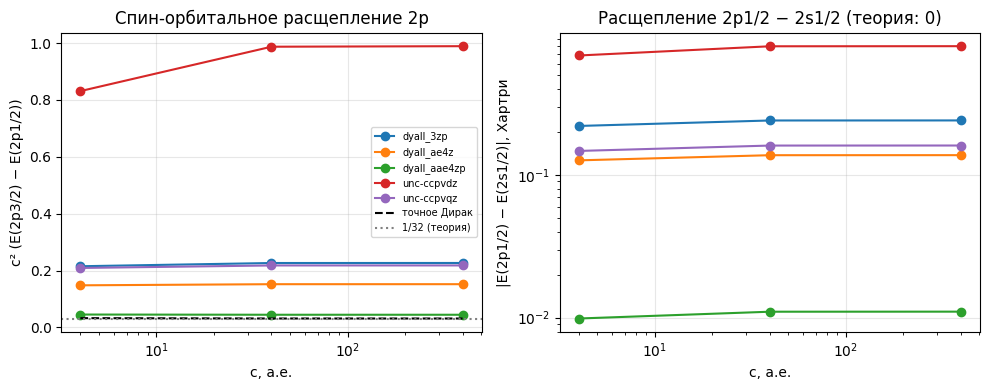

In [102]:

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for name in basis_sets:
    cs  = light_speeds
    so  = [(results[(name, c)]['E2p32'] - results[(name, c)]['E2p12'])*c*c for c in cs]s
    sp  = [abs(results[(name, c)]['E2p12'] - results[(name, c)]['E2s']) for c in cs]
    ax[0].plot(cs, so, 'o-', label=name)
    ax[1].plot(cs, [max(x, 1e-16) for x in sp], 'o-', label=name)

ax[0].plot(light_speeds, [(E_dirac(2, 1.5, c) - E_dirac(2, 0.5, c))*c*c for c in light_speeds], 'k--', label='точное Дирак')
ax[0].axhline(1/32, color='gray', ls=':', label='1/32 (теория)')
ax[0].set_xscale('log'); ax[0].set_xlabel('c, а.е.'); ax[0].set_ylabel('c² (E(2p3/2) − E(2p1/2))')
ax[0].set_title('Спин-орбитальное расщепление 2p'); ax[0].legend(fontsize=7)

ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('c, а.е.'); ax[1].set_ylabel('|E(2p1/2) − E(2s1/2)|, Хартри')
ax[1].set_title('Расщепление 2p1/2 − 2s1/2 (теория: 0)')
for a in ax: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('h_dhf_splittings.png', dpi=150); plt.show()